<h1 style="text-align: center">Exploring Ebay's Car Sales</h1>
<br>
<img src="assets\img\logo.png" width="550px">
<br>

<h1>1. Introduction</h1>
<p>The dataset was originally scraped and uploaded to Kaggle. The version of the dataset we are working with is a sample of 50,000 data points,<br> a less-cleaned version of the data.</p>
<p>The data dictionary provided with data is as follows:
<ul>
<li>dateCrawled - When this ad was first crawled. All field-values are taken from this date.</li>
<li>name - Name of the car.</li>
<li>seller - Whether the seller is private or a dealer.</li>
<li>offerType - The type of listing</li>
<li>price - The price on the ad to sell the car.</li>
<li>abtest - Whether the listing is included in an A/B test.</li>
<li>vehicleType - The vehicle Type.</li>
<li>yearOfRegistration - The year in which which year the car was first registered.</li>
<li>gearbox - The transmission type.</li>
<li>powerPS - The power of the car in PS.</li>
<li>model - The car model name.</li>
<li>kilometer - How many kilometers the car has driven.</li>
<li>monthOfRegistration - The month in which which year the car was first registered.</li>
<li>fuelType - What type of fuel the car uses.</li>
<li>brand - The brand of the car.</li>
<li>notRepairedDamage - If the car has a damage which is not yet repaired.</li>
<li>dateCreated - The date on which the eBay listing was created.</li>
<li>nrOfPictures - The number of pictures in the ad.</li>
<li>postalCode - The postal code for the location of the vehicle.</li>
<li>lastSeenOnline - When the crawler saw this ad last online.</li></ul>
The aim of this project is to clean the data and analyze the included used car listings.</p>

<h1>2. Preparing the Dataset</h1>
<p>Importing the libraries so that we will be able to use them for the purpose of analyzation and visualization</p>

In [1]:
# base libraries
import pandas as pd
import numpy as np
# libraries for visualisation
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib
import seaborn as sns
%matplotlib inline
# other libraries
import datetime
from collections import Counter;
#this class color is just to adjust the color of the printed text or styles)
class color:
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

#color.BOLD + 'Hello World !' + color.END

In [2]:
# load the dataset into notebook
autos_df = pd.read_csv("assets\csv_files\\autos.csv")
# print info of the dataset
autos_df.info()
# print the first five rows
autos_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   dateCrawled          50000 non-null  object
 1   name                 50000 non-null  object
 2   seller               50000 non-null  object
 3   offerType            50000 non-null  object
 4   price                50000 non-null  object
 5   abtest               50000 non-null  object
 6   vehicleType          44905 non-null  object
 7   yearOfRegistration   50000 non-null  int64 
 8   gearbox              47320 non-null  object
 9   powerPS              50000 non-null  int64 
 10  model                47242 non-null  object
 11  odometer             50000 non-null  object
 12  monthOfRegistration  50000 non-null  int64 
 13  fuelType             45518 non-null  object
 14  brand                50000 non-null  object
 15  notRepairedDamage    40171 non-null  object
 16  date

,dateCrawled,name,seller,offerType,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,odometer,monthOfRegistration,fuelType,brand,notRepairedDamage,dateCreated,nrOfPictures,postalCode,lastSeen
0,26/3/2016 17:47,Peugeot_807_160_NAVTECH_ON_BOARD,privat,Angebot,"$5,000",control,bus,2004,manuell,158,andere,"150,000km",3,lpg,peugeot,nein,26/3/2016 0:00,0,79588,6/4/2016 6:45
1,4/4/2016 13:38,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,privat,Angebot,"$8,500",control,limousine,1997,automatik,286,7er,"150,000km",6,benzin,bmw,nein,4/4/2016 0:00,0,71034,6/4/2016 14:45
2,26/3/2016 18:57,Volkswagen_Golf_1.6_United,privat,Angebot,"$8,990",test,limousine,2009,manuell,102,golf,"70,000km",7,benzin,volkswagen,nein,26/3/2016 0:00,0,35394,6/4/2016 20:15
3,12/3/2016 16:58,Smart_smart_fortwo_coupe_softouch/F1/Klima/Pan...,privat,Angebot,"$4,350",control,kleinwagen,2007,automatik,71,fortwo,"70,000km",6,benzin,smart,nein,12/3/2016 0:00,0,33729,15/3/2016 3:16
4,1/4/2016 14:38,Ford_Focus_1_6_Benzin_TÜV_neu_ist_sehr_gepfleg...,privat,Angebot,"$1,350",test,kombi,2003,manuell,0,focus,"150,000km",7,benzin,ford,nein,1/4/2016 0:00,0,39218,1/4/2016 14:38


<h1>3. Data Cleaning and Data Standardization</h1>
<p>Dirty data can produce inaccurate results and therefore, we need to clean the data before we can analyse them. This includes removing any duplicate rows, dropping irrelevent columns and handling missing data</p>

In [3]:
# print out all the column names in the dataset
print(autos_df.columns.values);

['dateCrawled' 'name' 'seller' 'offerType' 'price' 'abtest' 'vehicleType'
 'yearOfRegistration' 'gearbox' 'powerPS' 'model' 'odometer'
 'monthOfRegistration' 'fuelType' 'brand' 'notRepairedDamage'
 'dateCreated' 'nrOfPictures' 'postalCode' 'lastSeen']


In [4]:
# rename the columns
autos_df.columns = ['date_crawled', 'name', 'seller', 'offer_type', 'price', 
                 'ab_test', 'vehicle_type', 'registration_year', 'gearbox',
                 'power_ps', 'model', 'odometer', 'registration_month',
                 'fuel_type', 'brand', 'unrepaired_damage', 'ad_created',
                 'num_photos', 'postcode', 'last_seen']
# print the first five rows
autos_df.head()

,date_crawled,name,seller,offer_type,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,num_photos,postcode,last_seen
0,26/3/2016 17:47,Peugeot_807_160_NAVTECH_ON_BOARD,privat,Angebot,"$5,000",control,bus,2004,manuell,158,andere,"150,000km",3,lpg,peugeot,nein,26/3/2016 0:00,0,79588,6/4/2016 6:45
1,4/4/2016 13:38,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,privat,Angebot,"$8,500",control,limousine,1997,automatik,286,7er,"150,000km",6,benzin,bmw,nein,4/4/2016 0:00,0,71034,6/4/2016 14:45
2,26/3/2016 18:57,Volkswagen_Golf_1.6_United,privat,Angebot,"$8,990",test,limousine,2009,manuell,102,golf,"70,000km",7,benzin,volkswagen,nein,26/3/2016 0:00,0,35394,6/4/2016 20:15
3,12/3/2016 16:58,Smart_smart_fortwo_coupe_softouch/F1/Klima/Pan...,privat,Angebot,"$4,350",control,kleinwagen,2007,automatik,71,fortwo,"70,000km",6,benzin,smart,nein,12/3/2016 0:00,0,33729,15/3/2016 3:16
4,1/4/2016 14:38,Ford_Focus_1_6_Benzin_TÜV_neu_ist_sehr_gepfleg...,privat,Angebot,"$1,350",test,kombi,2003,manuell,0,focus,"150,000km",7,benzin,ford,nein,1/4/2016 0:00,0,39218,1/4/2016 14:38


In [5]:
# display basic statistical information for every column in the dataset
autos_df.describe(include = 'all')

,date_crawled,name,seller,offer_type,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,num_photos,postcode,last_seen
count,50000,50000,50000,50000,50000,50000,44905,50000.000000,47320,50000.000000,47242,50000,50000.000000,45518,50000,40171,50000,50000.0,50000.000000,50000
unique,12073,38754,2,2,2357,2,8,NaN,2,NaN,245,13,NaN,7,40,2,76,NaN,NaN,10432
top,28/3/2016 14:49,Ford_Fiesta,privat,Angebot,$0,test,limousine,NaN,manuell,NaN,golf,"150,000km",NaN,benzin,volkswagen,nein,3/4/2016 0:00,NaN,NaN,6/4/2016 2:45
freq,15,78,49999,49999,1421,25756,12859,NaN,36993,NaN,4024,32424,NaN,30107,10687,35232,1946,NaN,NaN,112
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2005.073280,NaN,116.355920,NaN,NaN,5.723360,NaN,NaN,NaN,NaN,0.0,50813.627300,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,105.712813,NaN,209.216627,NaN,NaN,3.711984,NaN,NaN,NaN,NaN,0.0,25779.747957,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000.000000,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.0,1067.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1999.000000,NaN,70.000000,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,0.0,30451.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2003.000000,NaN,105.000000,NaN,NaN,6.000000,NaN,NaN,NaN,NaN,0.0,49577.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2008.000000,NaN,150.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,0.0,71540.000000,NaN


In [6]:
# count number of unique rows for particular column
autos_df["num_photos"].value_counts()

0    50000
Name: num_photos, dtype: int64

In [7]:
# drop any null rows
autos_df.dropna(inplace = True)
# drop irrelevant columns: seller, offer_type and num_photos
autos_df.drop(['seller', 'offer_type', 'num_photos'], axis=1, inplace=True)
# print out all the column names in the dataset
print(autos_df.columns.values);

['date_crawled' 'name' 'price' 'ab_test' 'vehicle_type'
 'registration_year' 'gearbox' 'power_ps' 'model' 'odometer'
 'registration_month' 'fuel_type' 'brand' 'unrepaired_damage' 'ad_created'
 'postcode' 'last_seen']


In [8]:
# display all unique values in column 'vehicle_type'
autos_df["vehicle_type"].drop_duplicates()

0             bus
1       limousine
3      kleinwagen
4           kombi
17          coupe
19            suv
21         cabrio
198        andere
Name: vehicle_type, dtype: object

In [9]:
# display all unique values in column 'gearbox'
autos_df["gearbox"].drop_duplicates()

0      manuell
1    automatik
Name: gearbox, dtype: object

In [10]:
# display all unique values in column 'fuel_type'
autos_df["fuel_type"].drop_duplicates()

0           lpg
1        benzin
7        diesel
258         cng
1127     hybrid
2357    elektro
4220     andere
Name: fuel_type, dtype: object

In [11]:
# display all unique values in column 'unrepaired_damage'
autos_df["unrepaired_damage"].drop_duplicates()

0     nein
28      ja
Name: unrepaired_damage, dtype: object

In [12]:
# define the german words and translated words
corrections = {
    'bus':'bus',
    'limousine':'limousine',
    'kleinwagen':'supermini',
    'kombi':'station_wagon',
    'coupe':'coupe',
    'suv':'suv',
    'cabrio':'cabrio',
    'andere' :'other',
    'manuell':'manual',
    'automatik':'automatic',
    'lpg':'lpg',
    'benzin':'petrol',
    'diesel':'diesel',
    'cng':'cng',
    'hybrid':'hybrid',
    'elektro':'electro',
    'nein':'no',
    'ja':'yes'
}
# replace all german words with translated words
for each in ['vehicle_type','gearbox','fuel_type','unrepaired_damage']:
    autos_df[each] = autos_df[each].map(corrections)

In [13]:
# display all unique values in column 'brand' and sort them in ascending order
autos_df["brand"].drop_duplicates().sort_values()

762        alfa_romeo
13               audi
1                 bmw
200         chevrolet
249          chrysler
163           citroen
53              dacia
318            daewoo
1159         daihatsu
162              fiat
4                ford
260             honda
235           hyundai
95             jaguar
1610             jeep
149               kia
5560             lada
3227           lancia
663        land_rover
19              mazda
29      mercedes_benz
22               mini
86         mitsubishi
61             nissan
16               opel
0             peugeot
21            porsche
9             renault
1789            rover
70               saab
37               seat
122             skoda
3               smart
136            subaru
331            suzuki
45             toyota
1130          trabant
2          volkswagen
75              volvo
Name: brand, dtype: object

In [14]:
# remove character that stored as text and change the datatype to float
autos_df["odometer"] = autos_df["odometer"].str.replace(',', '').str.replace('km', '').astype(float)
autos_df["price"] = autos_df["price"].str.replace(',','').str.replace('$','').astype(float)
autos_df.rename({"Odometer":"odometer_km"}, axis=1, inplace=True)

<h1>4. Exploring the Data</h1>
<p>Data exploration is the initial step in data analysis, where we explore a large data set in an unstructured way to uncover initial patterns, characteristics, and points of interest. This process isn’t meant to reveal every bit of information a dataset holds, but rather to help create a broad picture of important trends and major points to study in greater detail.</p>
<p>This process makes deeper analysis easier because it can help target future searches and begin the process of excluding irrelevant data points and search paths that may turn up no results. More importantly, it helps build a familiarity with the existing information that makes finding better answers much simpler.</p>

In [15]:
# count the vehicle available in the list based on brand and sort them in descending order
autos_df.groupby(["brand"]).size().reset_index(name='counts').sort_values(by=["counts"], ascending=False).head(10)

,brand,counts
37,volkswagen,7239
2,bmw,4097
24,opel,3592
20,mercedes_benz,3587
1,audi,3208
10,ford,2339
27,renault,1591
25,peugeot,1050
9,fiat,832
30,seat,665


In [16]:
# copy all data for each top brand: volkswagen, bmw and mercedes into new dataframe
volk_df = autos_df.loc[autos_df['brand'] == "volkswagen"]
bmw_df = autos_df.loc[autos_df['brand'] == "bmw"]
mercedes_df = autos_df.loc[autos_df['brand'] == "mercedes_benz"]
# combine all 3 dataframes into 1 dataframe
combine = [volk_df, bmw_df, mercedes_df]
top_brand = volk_df.append([bmw_df, mercedes_df])
# export the 'top_brand' dataframe into csv file
top_brand.to_csv('assets/csv_files/top_brand.csv', index=False)
# print the first 10 rows
top_brand.head(10)

,date_crawled,name,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,postcode,last_seen
2,26/3/2016 18:57,Volkswagen_Golf_1.6_United,8990.0,test,limousine,2009,manual,102,golf,70000.0,7,petrol,volkswagen,no,26/3/2016 0:00,35394,6/4/2016 20:15
7,16/3/2016 18:55,Golf_IV_1.9_TDI_90PS,1990.0,control,limousine,1998,manual,90,golf,150000.0,12,diesel,volkswagen,no,16/3/2016 0:00,53474,7/4/2016 3:17
17,29/3/2016 11:46,Volkswagen_Scirocco_2_G60,5500.0,test,coupe,1990,manual,205,scirocco,150000.0,6,petrol,volkswagen,no,29/3/2016 0:00,74821,5/4/2016 20:46
26,3/4/2016 22:46,Volkswagen_Polo_Fox,777.0,control,supermini,1992,manual,54,polo,125000.0,2,petrol,volkswagen,no,3/4/2016 0:00,38110,5/4/2016 23:46
38,21/3/2016 15:51,Volkswagen_Golf_1.4_Special,2850.0,control,limousine,2002,manual,75,golf,125000.0,2,petrol,volkswagen,no,21/3/2016 0:00,63674,28/3/2016 12:16
40,7/3/2016 14:50,VW_Golf__4_Cabrio_2.0_GTI_16V___Leder_MFA_Alus...,3500.0,control,cabrio,1999,manual,150,golf,150000.0,1,petrol,volkswagen,no,7/3/2016 0:00,6780,12/3/2016 2:15
57,12/3/2016 11:46,Volkswagen_Passat_Variant_2.0_TDI_DPF_Trendline,4100.0,test,station_wagon,2007,manual,140,passat,150000.0,2,diesel,volkswagen,no,12/3/2016 0:00,27404,20/3/2016 9:49
58,30/3/2016 12:25,Volkswagen_Golf_1.4,4200.0,control,limousine,2004,manual,75,golf,125000.0,11,petrol,volkswagen,no,30/3/2016 0:00,56073,1/4/2016 8:29
62,12/3/2016 17:41,Volkswagen_Golf_Plus_1.6_FSI_Goal,6300.0,test,bus,2006,manual,116,golf,125000.0,4,petrol,volkswagen,no,12/3/2016 0:00,80939,3/4/2016 8:16
96,7/3/2016 20:56,Volkswagen_Golf_Variant_1.9_TDI_Joker,1000.0,test,station_wagon,1997,manual,110,golf,150000.0,6,diesel,volkswagen,no,7/3/2016 0:00,96106,5/4/2016 23:45


In [17]:
# list all car brand in 'top_brand'
top_brand["brand"].drop_duplicates()

2        volkswagen
1               bmw
29    mercedes_benz
Name: brand, dtype: object

In [18]:
# count total gearbox for each to brand in 2006
top_brand.loc[top_brand['registration_year'] == 2006].groupby(["brand", "gearbox"]).size().reset_index(name='counts')

,brand,gearbox,counts
0,bmw,automatic,91
1,bmw,manual,173
2,mercedes_benz,automatic,131
3,mercedes_benz,manual,61
4,volkswagen,automatic,84
5,volkswagen,manual,365


In [19]:
# count total gearbox for each to brand in 2004
top_brand.loc[top_brand['registration_year'] == 2004].groupby(["brand", "gearbox"]).size().reset_index(name='counts')

,brand,gearbox,counts
0,bmw,automatic,109
1,bmw,manual,165
2,mercedes_benz,automatic,141
3,mercedes_benz,manual,91
4,volkswagen,automatic,48
5,volkswagen,manual,288


In [20]:
# count total gearbox for each to brand in 2005
top_brand.loc[top_brand['registration_year'] == 2005].groupby(["brand", "gearbox"]).size().reset_index(name='counts')

,brand,gearbox,counts
0,bmw,automatic,111
1,bmw,manual,178
2,mercedes_benz,automatic,144
3,mercedes_benz,manual,80
4,volkswagen,automatic,67
5,volkswagen,manual,286


In [21]:
# count the vehicle available in the list based on year of registration and sort them in descending order
autos_df.groupby(["registration_year"]).size().reset_index(name='counts').sort_values(by=["counts"], ascending=False).head(10)

,registration_year,counts
56,2006,2250
54,2004,2182
55,2005,2162
53,2003,2133
49,1999,2121
51,2001,2016
50,2000,1985
52,2002,1936
57,2007,1935
58,2008,1904


In [22]:
# copy all data for each top year of registration: 2006, 2004 and 2005 into new dataframe
reg2006_df = autos_df.loc[autos_df['registration_year'] == 2006]
reg2004_df = autos_df.loc[autos_df['registration_year'] == 2004]
reg2005_df = autos_df.loc[autos_df['registration_year'] == 2005]
# combine all 2 dataframes into 1 dataframe
combine = [reg2006_df, reg2004_df, reg2005_df]
top_reg_year = pd.concat(combine)
# print the first 10 rows
top_reg_year.head(10)

,date_crawled,name,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,postcode,last_seen
33,15/3/2016 12:25,Audi_A3_2.0_TDI_Sportback_DPF_Kupplung_defekt_...,4800.0,test,station_wagon,2006,manual,140,a3,150000.0,8,diesel,audi,no,15/3/2016 0:00,61169,7/4/2016 13:15
62,12/3/2016 17:41,Volkswagen_Golf_Plus_1.6_FSI_Goal,6300.0,test,bus,2006,manual,116,golf,125000.0,4,petrol,volkswagen,no,12/3/2016 0:00,80939,3/4/2016 8:16
74,6/3/2016 2:00,Opel_Kombi,1500.0,control,station_wagon,2006,manual,0,astra,150000.0,3,petrol,opel,no,6/3/2016 0:00,23627,6/4/2016 1:46
91,5/3/2016 21:49,BMW_120i,7999.0,test,limousine,2006,manual,150,1er,125000.0,4,petrol,bmw,no,5/3/2016 0:00,30419,7/4/2016 8:44
109,21/3/2016 18:37,Seat_Cordoba,3399.0,test,limousine,2006,manual,75,cordoba,125000.0,6,petrol,seat,no,21/3/2016 0:00,48301,6/4/2016 19:47
195,3/4/2016 11:43,Fiat_Grande_Punto_1.4_16V_Sport,3300.0,control,supermini,2006,manual,95,andere,125000.0,12,petrol,fiat,no,3/4/2016 0:00,40599,7/4/2016 12:45
212,14/3/2016 13:45,Porsche_Boxster_Tiptronic_S_unfallfrei_Navi,26300.0,test,cabrio,2006,automatic,245,boxster,40000.0,10,petrol,porsche,no,14/3/2016 0:00,69509,5/4/2016 14:18
233,19/3/2016 22:52,Volkswagen_Phaeton_3.0_TDI,10500.0,test,limousine,2006,automatic,224,phaeton,150000.0,6,diesel,volkswagen,no,19/3/2016 0:00,24983,5/4/2016 21:16
294,4/4/2016 20:50,Volkswagen_Golf_1.4_Sportline,3699.0,control,limousine,2006,manual,75,golf,150000.0,7,petrol,volkswagen,no,4/4/2016 0:00,89542,6/4/2016 23:17
331,1/4/2016 16:48,Suzuki_Grand_Vitara_1.9_DDiS_Comfort_DPF,7650.0,control,suv,2006,manual,129,grand,150000.0,5,diesel,suzuki,no,1/4/2016 0:00,74670,5/4/2016 12:16


In [23]:
# display all unique values in column 'registration_year' and sort them in ascending order
top_reg_year["registration_year"].drop_duplicates()

33    2006
0     2004
51    2005
Name: registration_year, dtype: int64

In [24]:
# count number of vehicle for every car brand from top 3 registration year
top_reg_year.groupby(["brand"]).size().reset_index(name='counts').sort_values(by=["counts"], ascending=False).head(10)

,brand,counts
36,volkswagen,1138
2,bmw,827
20,mercedes_benz,648
24,opel,644
1,audi,604
10,ford,498
27,renault,299
25,peugeot,252
30,seat,137
5,citroen,133


In [25]:
# average price for every vehicle type produced by mercedes
print("Average Price for Each Vehicle Type (Mercedes)")
mercedes_df[['vehicle_type', 'price']].groupby(['vehicle_type'], as_index=False).mean().sort_values(by='price', ascending=False)

Average Price for Each Vehicle Type (Mercedes)


,vehicle_type,price
7,suv,17979.036082
1,cabrio,17494.513433
0,bus,11014.822981
2,coupe,10848.500000
5,station_wagon,7687.889344
3,limousine,7215.690539
4,other,5897.666667
6,supermini,2497.722892


In [26]:
# average price for every vehicle type produced by bmw
print("Average Price for Each Vehicle Type (BMW)")
bmw_df[['vehicle_type', 'price']].groupby(['vehicle_type'], as_index=False).mean().sort_values(by='price', ascending=False)

Average Price for Each Vehicle Type (BMW)


,vehicle_type,price
0,bus,25608.000000
7,suv,18741.147826
1,cabrio,12830.411765
2,coupe,8819.565310
3,limousine,8410.970845
5,station_wagon,8000.333683
6,supermini,3674.194444
4,other,2500.904762


In [27]:
# average price for every vehicle type produced by volkswagen
print("Average Price for Each Vehicle Type (Volkswagen)")
volk_df[['vehicle_type', 'price']].groupby(['vehicle_type'], as_index=False).mean().sort_values(by='price', ascending=False)

Average Price for Each Vehicle Type (Volkswagen)


,vehicle_type,price
7,suv,17062.548223
2,coupe,9906.016575
0,bus,9883.048485
1,cabrio,7371.515244
3,limousine,6562.896662
5,station_wagon,5445.812874
4,other,4467.862069
6,supermini,2797.469115


In [28]:
# export dataframes into csv format
volk_df.to_csv('assets/csv_files//volkswagen.csv', index=False)
bmw_df.to_csv('assets/csv_files//bmw.csv', index=False)
mercedes_df.to_csv('assets/csv_files/mercedes.csv', index=False)

In [29]:
#adib
# variation of brands
top_brands = autos_df["brand"].value_counts(normalize=True).sort_values(ascending = False).head(20).index
top_brands

Index(['volkswagen', 'bmw', 'opel', 'mercedes_benz', 'audi', 'ford', 'renault',
       'peugeot', 'fiat', 'seat', 'skoda', 'nissan', 'mazda', 'citroen',
       'toyota', 'smart', 'hyundai', 'mini', 'volvo', 'mitsubishi'],
      dtype='object')

In [30]:
#get the mean price for each brand
mean_prices = {}

for brands in top_brands:
    selected_brand = autos_df[autos_df['brand'] == brands] 
    price_mean = selected_brand['price'].mean() #calculate the mean of the `price`
    mean_prices[brands] = int(price_mean)  
    #print(price_mean)
    
sorted(mean_prices.items(), key=lambda kv: kv[1],reverse=True)

[('mini', 10897),
 ('audi', 10443),
 ('ford', 9505),
 ('mercedes_benz', 9452),
 ('bmw', 9077),
 ('skoda', 6881),
 ('opel', 6819),
 ('volkswagen', 6340),
 ('hyundai', 5859),
 ('toyota', 5481),
 ('volvo', 5429),
 ('nissan', 5250),
 ('seat', 4887),
 ('mazda', 4832),
 ('citroen', 4082),
 ('smart', 3893),
 ('mitsubishi', 3769),
 ('peugeot', 3411),
 ('fiat', 3216),
 ('renault', 2854)]

In [31]:
#get the mean mileage for each brand
mean_mileage = {}

for brands in top_brands:
    selected_brand = autos_df[autos_df['brand'] == brands] 
    mileage_mean = selected_brand['odometer'].mean() #calculate the mean of the 'odometer_km'
    mean_mileage[brands] = int(mileage_mean) 
    #print(price_mean)
    
sorted(mean_mileage.items(), key=lambda kv: kv[1],reverse=True)

[('volvo', 138575),
 ('bmw', 131670),
 ('mercedes_benz', 129880),
 ('opel', 127626),
 ('mitsubishi', 126607),
 ('audi', 126494),
 ('volkswagen', 126386),
 ('renault', 125895),
 ('peugeot', 124919),
 ('ford', 122986),
 ('mazda', 122130),
 ('seat', 119007),
 ('citroen', 116804),
 ('nissan', 116467),
 ('toyota', 114672),
 ('fiat', 113756),
 ('skoda', 108299),
 ('hyundai', 102526),
 ('smart', 96586),
 ('mini', 87364)]

In [32]:
#stored the mean price into bmp_series & mean mileage into bmm_series
bmp_series = pd.Series(mean_prices)
bmm_series = pd.Series(mean_mileage)

In [33]:
#to find out if there is any relationship between mileage and the price of a car
brand_price_mileage = pd.DataFrame(bmp_series, columns=['mean_price'])
brand_price_mileage['average_mileage'] = bmm_series
brand_price_mileage

,mean_price,average_mileage
volkswagen,6340,126386
bmw,9077,131670
opel,6819,127626
mercedes_benz,9452,129880
audi,10443,126494
ford,9505,122986
renault,2854,125895
peugeot,3411,124919
fiat,3216,113756
seat,4887,119007


In [34]:
#categorize 'odometer_km' into different categories
bins = [0, 10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000, 200000]
labels = ['<10000', '10001-20000', '20001-30000', '30001-40000', '40001-50000', '50001-60000', '60001-70000', '70001-80000', '80001-90000', '90001-100000', '>100000']
autos_df['mileage_range'] = pd.cut(autos_df['odometer'], bins=bins, labels=labels, include_lowest=True)

autos_df.head()

,date_crawled,name,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,postcode,last_seen,mileage_range
0,26/3/2016 17:47,Peugeot_807_160_NAVTECH_ON_BOARD,5000.0,control,bus,2004,manual,158,andere,150000.0,3,lpg,peugeot,no,26/3/2016 0:00,79588,6/4/2016 6:45,>100000
1,4/4/2016 13:38,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,8500.0,control,limousine,1997,automatic,286,7er,150000.0,6,petrol,bmw,no,4/4/2016 0:00,71034,6/4/2016 14:45,>100000
2,26/3/2016 18:57,Volkswagen_Golf_1.6_United,8990.0,test,limousine,2009,manual,102,golf,70000.0,7,petrol,volkswagen,no,26/3/2016 0:00,35394,6/4/2016 20:15,60001-70000
3,12/3/2016 16:58,Smart_smart_fortwo_coupe_softouch/F1/Klima/Pan...,4350.0,control,supermini,2007,automatic,71,fortwo,70000.0,6,petrol,smart,no,12/3/2016 0:00,33729,15/3/2016 3:16,60001-70000
4,1/4/2016 14:38,Ford_Focus_1_6_Benzin_TÜV_neu_ist_sehr_gepfleg...,1350.0,test,station_wagon,2003,manual,0,focus,150000.0,7,petrol,ford,no,1/4/2016 0:00,39218,1/4/2016 14:38,>100000


In [35]:
#approximate the current age for each car
autos_df['age']=2021-autos_df['registration_year']
autos_df.head()

,date_crawled,name,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,postcode,last_seen,mileage_range,age
0,26/3/2016 17:47,Peugeot_807_160_NAVTECH_ON_BOARD,5000.0,control,bus,2004,manual,158,andere,150000.0,3,lpg,peugeot,no,26/3/2016 0:00,79588,6/4/2016 6:45,>100000,17
1,4/4/2016 13:38,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,8500.0,control,limousine,1997,automatic,286,7er,150000.0,6,petrol,bmw,no,4/4/2016 0:00,71034,6/4/2016 14:45,>100000,24
2,26/3/2016 18:57,Volkswagen_Golf_1.6_United,8990.0,test,limousine,2009,manual,102,golf,70000.0,7,petrol,volkswagen,no,26/3/2016 0:00,35394,6/4/2016 20:15,60001-70000,12
3,12/3/2016 16:58,Smart_smart_fortwo_coupe_softouch/F1/Klima/Pan...,4350.0,control,supermini,2007,automatic,71,fortwo,70000.0,6,petrol,smart,no,12/3/2016 0:00,33729,15/3/2016 3:16,60001-70000,14
4,1/4/2016 14:38,Ford_Focus_1_6_Benzin_TÜV_neu_ist_sehr_gepfleg...,1350.0,test,station_wagon,2003,manual,0,focus,150000.0,7,petrol,ford,no,1/4/2016 0:00,39218,1/4/2016 14:38,>100000,18


In [36]:
#mirahanis
#Categorized the registration years for each brands to analyze the trend or what type of brand that consistently registered within the particular years to the websites.
brand_1999 = autos_df.loc[autos_df['registration_year'] <= 1999]
value_counts1 = brand_1999.brand.value_counts()
car_counts1 = pd.DataFrame(value_counts1)
car_counts1 = car_counts1.reset_index()
car_counts1.columns = ['Brand Name', '19XX - 1999']

brand_2003 = autos_df.loc[autos_df['registration_year'] == 2003]
value_counts2 =  brand_2003.brand.value_counts()
car_counts2 = pd.DataFrame(value_counts2)
car_counts2 = car_counts2.reset_index()
car_counts2.columns = ['Brand Name', '2003']

brand_2008 = autos_df.loc[autos_df['registration_year'] == 2008]
value_counts3 =  brand_2008.brand.value_counts()
car_counts3 = pd.DataFrame(value_counts3)
car_counts3 = car_counts3.reset_index()
car_counts3.columns = ['Brand Name', '2008']

brand_2013 = autos_df.loc[autos_df['registration_year'] == 2013]
value_counts4 =  brand_2013.brand.value_counts()
car_counts4 = pd.DataFrame(value_counts4)
car_counts4 = car_counts4.reset_index()
car_counts4.columns = ['Brand Name', '2013']

brand_2018 = autos_df.loc[autos_df['registration_year'] == 2018]
value_counts5 =  brand_2018.brand.value_counts()
car_counts5 = pd.DataFrame(value_counts5)
car_counts5 = car_counts5.reset_index()
car_counts5.columns = ['Brand Name', '2018']

car_counts = pd.concat([car_counts1,car_counts2,car_counts3,car_counts4,car_counts5],axis=1)
print(color.BOLD + "\t\nThe number of brand car being registered through out years (5 years gap)"+ color.END)
display(car_counts.head(26))

	
The number of brand car being registered through out years (5 years gap)


,Brand Name,19XX - 1999,Brand Name,2003,Brand Name,2008,Brand Name,2013,Brand Name,2018
0,volkswagen,2333,volkswagen,338.0,volkswagen,332.0,volkswagen,186.0,bmw,1.0
1,opel,1096,opel,242.0,bmw,266.0,audi,82.0,NaN,NaN
2,bmw,1068,mercedes_benz,242.0,audi,232.0,mercedes_benz,81.0,NaN,NaN
3,mercedes_benz,993,bmw,220.0,mercedes_benz,183.0,bmw,50.0,NaN,NaN
4,audi,662,ford,172.0,opel,159.0,ford,45.0,NaN,NaN
5,ford,531,audi,167.0,ford,121.0,opel,33.0,NaN,NaN
6,renault,412,renault,153.0,peugeot,66.0,skoda,32.0,NaN,NaN
7,peugeot,186,peugeot,103.0,fiat,46.0,mini,23.0,NaN,NaN
8,fiat,166,fiat,69.0,skoda,45.0,seat,22.0,NaN,NaN
9,nissan,145,seat,41.0,renault,43.0,hyundai,20.0,NaN,NaN


In [37]:
# observe on what type of vehicle tend to be seen by buyers from the ads created
car_type=autos_df.groupby('vehicle_type')['last_seen'].nunique()
car_type=car_type.to_frame()
display(car_type)

,last_seen
vehicle_type,
bus,2009
cabrio,1328
coupe,1208
limousine,4301
other,217
station_wagon,3432
supermini,3809
suv,1102


To count the number of gearbox type being used on which vehicle and the A/B Test. By doing this,we can see between manual and automatik type of gearbox, on each type of vehicle either it was a control test or test that most likely want to be sell.

With the help of ascending set to True, we can see manual vehicle is much bigger amount compared to automatik whether it was control/ test, means most people who sell their vehicle on ebay, it most likely the manual vehicle.

In [38]:
pd.DataFrame(autos_df.groupby(["ab_test", "vehicle_type"])
             ["gearbox"].value_counts(ascending=True))

gearbox
ab_test vehicle_type  gearbox           
control bus           automatic      304
                      manual        1340
        cabrio        automatic      306
                      manual         873
        coupe         automatic      324
                      manual         653
        limousine     automatic     1259
                      manual        3613
        other         automatic       15
                      manual          93
        station_wagon automatic      961
                      manual        2573
        supermini     automatic      295
                      manual        3576
        suv           manual         364
                      automatic      417
test    bus           automatic      301
                      manual        1429
        cabrio        automatic      375
                      manual         902
        coupe         automatic      329
                      manual         645
        limousine     automatic     1467
                      manual        3886
        other         automatic       12
                      manual         109
        station_wagon automatic      977
                      manual        2694
        supermini     automatic      349
                      manual        3761
        suv           automatic      399
                      manual         446

In order to not disturb the original dataframe, we will use .copy() to take the exact same data to a new dataframe
Giving a new column name, which taken from the original data to simplify the data handling
To see the average power per second of the top 10 brands from list in the new dataframe.
Transform means into a dictionary for mapping in analyse data in the future
to_dict is used to convert a dataframe into a dictionary of series or list like data type depending on orient parameter.

In [39]:
df_raw = autos_df.copy() 
df_raw['Brand Name'] = autos_df['brand'] 
means = df_raw.groupby('Brand Name')['power_ps'].mean()
display(means.head(10))
map_means = means.to_dict()
print("\nThe dictionary for mapping the average power for each brand names\n")
display(map_means)

Brand Name
alfa_romeo    139.678862
audi          172.852868
bmw           177.336100
chevrolet     136.840796
chrysler      149.625000
citroen        97.866935
dacia          86.869159
daewoo         71.122449
daihatsu       59.604938
fiat           77.745192
Name: power_ps, dtype: float64


The dictionary for mapping the average power for each brand names



{'alfa_romeo': 139.6788617886179,
 'audi': 172.85286783042395,
 'bmw': 177.33609958506224,
 'chevrolet': 136.8407960199005,
 'chrysler': 149.625,
 'citroen': 97.86693548387096,
 'dacia': 86.86915887850468,
 'daewoo': 71.12244897959184,
 'daihatsu': 59.60493827160494,
 'fiat': 77.7451923076923,
 'ford': 111.23514322359983,
 'honda': 115.42279411764706,
 'hyundai': 108.45430107526882,
 'jaguar': 220.20338983050848,
 'jeep': 184.75,
 'kia': 116.8876811594203,
 'lada': 67.21052631578948,
 'lancia': 92.05882352941177,
 'land_rover': 155.2289156626506,
 'mazda': 118.54702495201535,
 'mercedes_benz': 162.14050738778923,
 'mini': 131.85597826086956,
 'mitsubishi': 113.27142857142857,
 'nissan': 101.80960854092527,
 'opel': 99.54092427616926,
 'peugeot': 95.96571428571428,
 'porsche': 306.2530612244898,
 'renault': 90.81583909490887,
 'rover': 98.51219512195122,
 'saab': 159.40322580645162,
 'seat': 104.99699248120301,
 'skoda': 104.94695787831513,
 'smart': 74.84018264840182,
 'subaru': 150.59

Import the datetime to change the object value for the Last Seen table to datetime
Create a new column to store this new binned column
Changing the datatype of Last Seen column to datetime
Create a new column to store this new binned column
Let us divide each hour in existing Date/Time column into four smaller bins of 15 mins each:[0mins -15mins], [15mins - 30mins], [30mins - 45mins] and [45mins - 60mins] This will allow us to visualize the time series more precisely.
Include the counting to see how many times it has being last seen for the same date and time.

In [40]:
#create a new column to store this new binned column
df_raw =autos_df.copy()
#changing the datatype of Last Seen column to datetime
df_raw['Last Seen'] = pd.to_datetime(df_raw['last_seen'])
#create a new column to store this new binned column
df_raw['BinnedHour']= df_raw['Last Seen'].dt.floor('15min')
#include the counting to see how many times it has being last seen for the same date and time.
display(df_raw['BinnedHour'].value_counts())

2016-05-04 12:15:00    256
2016-05-04 12:45:00    199
2016-06-04 01:15:00    186
2016-07-04 04:15:00    185
2016-06-04 21:15:00    185
                      ... 
2016-03-22 19:00:00      1
2016-03-13 15:00:00      1
2016-03-18 18:00:00      1
2016-03-23 04:45:00      1
2016-08-03 21:45:00      1
Name: BinnedHour, Length: 2325, dtype: int64

Separated a column [BinnedHour] to it several columns[Time/Day/Month]
Analyzing in which days where buyer/visitor, hours visits the website the most.

In [41]:
df_raw['Weekday']=df_raw['BinnedHour'].dt.day_name()
df_raw['Day']=df_raw['BinnedHour'].dt.day
df_raw['Minute']=df_raw['BinnedHour'].dt.minute
df_raw['Month']=df_raw['BinnedHour'].dt.month
df_raw['Hour']=df_raw['BinnedHour'].dt.hour
def count_rows(rows):
  return len(rows)
by_cross = df_raw.groupby(['Weekday','Hour']).apply(count_rows)
pivot=by_cross.unstack()
display(pivot)

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Weekday,,,,,,,,,,,,,,,,,,,,,
Friday,77,85,74,111,98,53,51,65,75,82,...,77,104,85,93,67,70,75,63,66,41
Monday,434,426,446,490,464,488,510,519,474,515,...,389,231,212,195,154,165,170,157,143,121
Saturday,373,409,399,361,399,426,423,423,471,431,...,481,511,486,462,445,434,424,432,431,400
Sunday,83,72,72,79,73,37,44,46,62,85,...,89,93,91,85,96,100,48,62,48,46
Thursday,95,97,91,94,110,119,139,154,143,194,...,176,187,159,192,177,170,164,144,136,119
Tuesday,53,59,51,56,64,68,59,87,70,90,...,109,105,107,125,114,107,97,89,77,59
Wednesday,102,108,98,73,71,105,115,125,152,132,...,451,441,313,347,457,404,434,442,396,413


Finding the car from the list that registered on the recent year between 2016 - 2020 by ascending order of Registration year

In [42]:
RegistrationRange = autos_df[autos_df["registration_year"].between(2016, 2020)]
display(RegistrationRange.sort_values(by="registration_year", ascending=True)) 

,date_crawled,name,price,ab_test,vehicle_type,registration_year,gearbox,power_ps,model,odometer,registration_month,fuel_type,brand,unrepaired_damage,ad_created,postcode,last_seen,mileage_range,age
1555,17/3/2016 1:00,Audi_Cabriolet____A5___NAVI_.XEN_._ALCANTARA.S...,37450.0,test,cabrio,2016,manual,177,andere,5000.0,3,petrol,audi,no,17/3/2016 0:00,95444,17/3/2016 7:38,<10000,5
31836,12/3/2016 13:46,Gelegenheit!_Seat_Ibiza_90PS__Neu__Werksgarant...,12800.0,control,supermini,2016,manual,90,ibiza,5000.0,3,petrol,seat,no,12/3/2016 0:00,79761,12/3/2016 13:46,<10000,5
32975,10/3/2016 16:46,BMW_X1_xDrive20d_Aut.Wunschfahrzeug_von_Werksa...,32900.0,control,suv,2016,automatic,190,x_reihe,10000.0,3,diesel,bmw,no,10/3/2016 0:00,94351,7/4/2016 13:50,<10000,5
32981,31/3/2016 16:52,Volkswagen_T6_California_Ocean_DSG/4Motion__SO...,64280.0,control,bus,2016,automatic,204,transporter,5000.0,1,diesel,volkswagen,no,31/3/2016 0:00,86167,6/4/2016 10:16,<10000,5
33744,24/3/2016 12:54,Audi_A4_2.0_TFSI_ultra_S_tronic_design,34900.0,test,limousine,2016,automatic,190,a4,5000.0,3,petrol,audi,no,24/3/2016 0:00,13435,5/4/2016 1:16,<10000,5
36818,27/3/2016 18:37,Porsche_991,350000.0,control,coupe,2016,manual,500,911,5000.0,3,petrol,porsche,no,27/3/2016 0:00,70499,27/3/2016 18:37,<10000,5
36892,11/3/2016 18:52,Audi_A3_1.2_TFSI_Ambition,19500.0,test,limousine,2016,manual,110,a3,5000.0,3,petrol,audi,no,11/3/2016 0:00,52382,14/3/2016 16:48,<10000,5
38567,21/3/2016 22:55,Ford_Fiesta_ECO_Boost_5_J_Garantie,13600.0,control,supermini,2016,manual,101,fiesta,5000.0,1,petrol,ford,no,21/3/2016 0:00,57489,23/3/2016 9:18,<10000,5
39425,22/3/2016 0:57,Mercedes_Benz_C_200_Avantgarde//Exclusive_NEU_...,42500.0,control,limousine,2016,manual,184,c_klasse,5000.0,3,petrol,mercedes_benz,no,21/3/2016 0:00,30916,29/3/2016 9:45,<10000,5
40269,20/3/2016 0:56,MINI_COOPER_CLUBMAN___Neuwagen_aus_Autogewinn,23540.0,control,station_wagon,2016,manual,136,clubman,5000.0,3,petrol,mini,no,19/3/2016 0:00,96170,28/3/2016 3:45,<10000,5


The average power per second for the top 20 vehicle type

In [43]:
print(color.PURPLE + '\n\t The average power per second for the top 20 vehicle type' + color.END)
print(autos_df.groupby('vehicle_type')['power_ps'].mean().sort_values(ascending = True).head(20))


	 The average power per second for the top 20 vehicle type
vehicle_type
supermini         75.557700
other             91.886463
bus              118.368702
limousine        135.960685
station_wagon    143.155031
cabrio           159.354642
suv              168.269988
coupe            182.189646
Name: power_ps, dtype: float64


In [44]:
# husna
#find the unique brands
brands = autos_df["brand"].value_counts().index

#Print common brand that represent more than 5% of total listings

brand_counts = autos_df['brand'].value_counts(normalize=True)
common_brands = brand_counts[brand_counts > .05].index
print(common_brands)

Index(['volkswagen', 'bmw', 'opel', 'mercedes_benz', 'audi', 'ford'], dtype='object')


In [45]:
#Print mean prices

brand_mean_prices = {}

for brand in common_brands:
    brand_only = autos_df[autos_df["brand"] == brand]
    mean_price = brand_only["price"].mean()
    brand_mean_prices[brand] = int(mean_price)
brand_mean_prices

#Column Mean Price and brand ascending

bmp_series = pd.Series(brand_mean_prices).sort_values(ascending = False)
pd.DataFrame(bmp_series, columns = ["mean_price"]) 

,mean_price
audi,10443
ford,9505
mercedes_benz,9452
bmw,9077
opel,6819
volkswagen,6340


In [46]:
# find the unique brands
brands = autos_df["brand"].value_counts().index

#10 Brand with Expensive Price by using mean price

brands_by_price = {}

for brand in brands:
    selected_brand = autos_df[autos_df["brand"] == brand]
    brands_by_price[brand] = round(selected_brand["price"].mean())

brands_by_price_tuples = []

for key in brands_by_price:
    brands_by_price_tuples.append((brands_by_price[key], key))

for value, key in sorted(brands_by_price_tuples, reverse=True)[:10]:
    print("{}: {}".format(key, value))

porsche: 48585
land_rover: 20361
jaguar: 12971
jeep: 11745
mini: 10898
audi: 10443
ford: 9506
mercedes_benz: 9453
bmw: 9078
chevrolet: 7200


In [47]:
# Creating Value Metric based on price-odometer(kilometres travelled)

higher_value_car = 10000 / 50000 # value of a car that costs 10,000 but driven 50000 kms
lower_value_car = 10000 / 150000 # value of a car that costs 10,000 but driven 150000 kms

print("Higher value car:", higher_value_car)
print("Lower value car:", lower_value_car)

Higher value car: 0.2
Lower value car: 0.06666666666666667


In [48]:
# create a new value column for the listings
autos_df["Value"] = autos_df["price"] / autos_df["odometer"]

# replace instances where unrepaired damage is null to False
autos_df["unrepaired_damage"] = autos_df["unrepaired_damage"].replace(np.nan, "nein", regex=True)

# halve the values of damaged cars
mask = autos_df["unrepaired_damage"] == "yes"
autos_df.loc[mask, "Value"] = autos_df.loc[mask, "Value"] * 0.50

# print lowest value
print("Lowest value", "{:f}".format(autos_df["Value"].sort_values().iloc[0]))

# print highest value
print("Highest value", autos_df["Value"].sort_values(ascending=False).iloc[0])

Lowest value 0.000000
Highest value 222.22222


In [49]:
#Top 10 Brand by value (price-odometer)

print ("Top 10 Brands With Best Value (Price/Odometer)")

brands_by_value = {}

for brand in brands:
    selected_brand = autos_df[autos_df["brand"] == brand]
    brands_by_value[brand] = round(selected_brand["Value"].mean(), 2)

brands_by_value_tuples = []

for key in brands_by_value:
    brands_by_value_tuples.append((brands_by_value[key], key))

for value, key in sorted(brands_by_value_tuples, reverse=True)[:10]:
    
    print("{}: {}".format(key, value))

Top 10 Brands With Best Value (Price/Odometer)
porsche: 2.01
land_rover: 0.59
jaguar: 0.32
mini: 0.27
jeep: 0.25
audi: 0.2
ford: 0.19
dacia: 0.18
chevrolet: 0.18
skoda: 0.15


In [50]:
bmp_series = pd.Series(brand_mean_prices).sort_values(ascending = False)
pd.DataFrame(bmp_series, columns = ["Mean Price"]) 

,Mean Price
audi,10443
ford,9505
mercedes_benz,9452
bmw,9077
opel,6819
volkswagen,6340


In [51]:
# 5 Recommendations for high value brands

brands_by_price_series = pd.Series(brands_by_price)
brands_by_value_series = pd.Series(brands_by_value)

pd.DataFrame({"mean_price": brands_by_price_series, "mean_value": brands_by_value_series}).sort_values("mean_value", ascending=False).head(5)

,mean_price,mean_value
porsche,48585,2.01
land_rover,20361,0.59
jaguar,12971,0.32
mini,10898,0.27
jeep,11745,0.25


In [52]:
aux_df = pd.concat([autos_df["brand"],autos_df["model"]], axis=1)
aux_df = aux_df.groupby(['brand','model']).size().reset_index().rename(columns={0:'count'})
aux_df

,brand,model,count
0,alfa_romeo,145,2
1,alfa_romeo,147,64
2,alfa_romeo,156,79
3,alfa_romeo,159,26
4,alfa_romeo,andere,48
...,...,...,...
282,volvo,v40,72
283,volvo,v50,26
284,volvo,v60,3
285,volvo,v70,72


In [53]:
#let's sort the new dataframe created in descending order by column 'count' to find the most common brand/model combinations.

aux_df.sort_values('count', ascending=False)

,brand,model,count
264,volkswagen,golf,2797
23,bmw,3er,2123
270,volkswagen,polo,1155
180,opel,corsa,1107
268,volkswagen,passat,1047
...,...,...,...
60,daihatsu,charade,1
76,ford,b_max,1
211,rover,freelander,1
212,rover,rangerover,1


<h1>5. Data Visualization</h1>
<p>Data visualization is the practice of translating information into a visual context, such as a map or graph, to make data easier for the human brain to understand and pull insights from. The main goal of data visualization is to make it easier to identify patterns, trends and outliers in large data sets. The term is often used interchangeably with others, including information graphics, information visualization and statistical graphics.</p>

C:\Users\ahmad\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


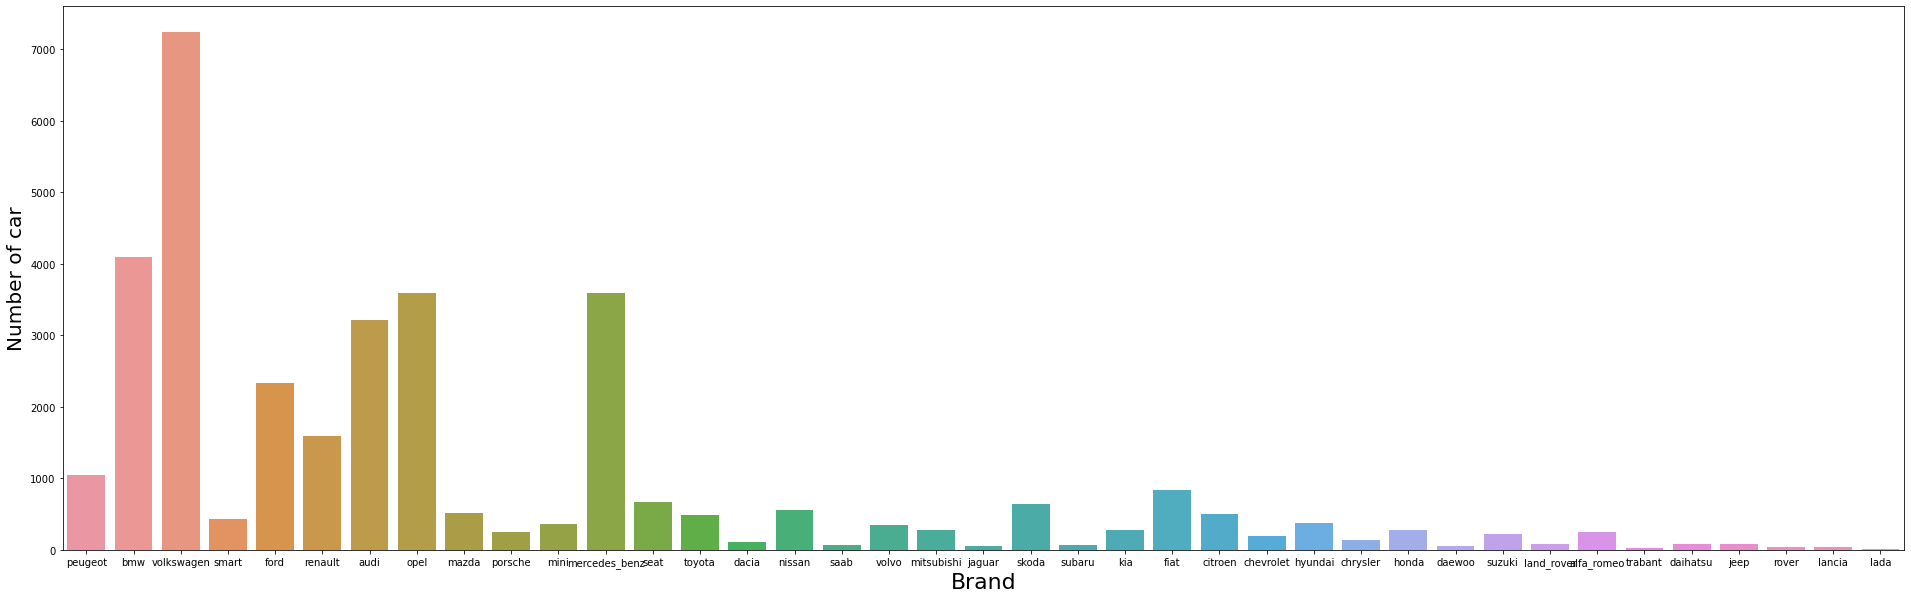

In [54]:
#visualization of all car brands sales

fig,ax=plt.subplots(figsize=(33,10))

plt.xticks(rotation='horizontal');
sns.countplot(autos_df['brand'])
plt.ylabel('Number of car', fontsize = 20);
plt.xlabel('Brand', fontsize=22);

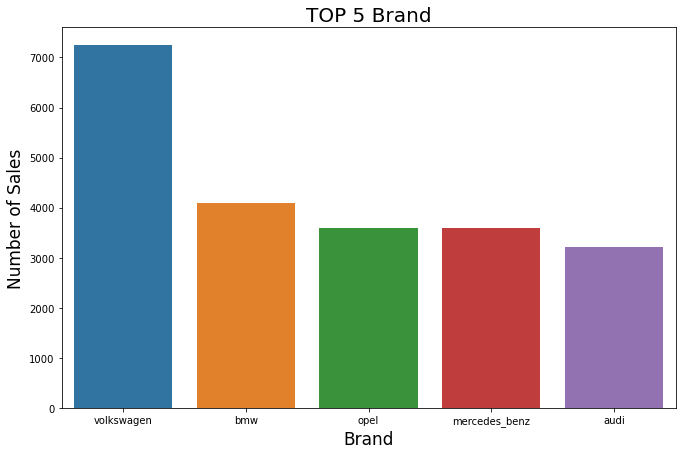

In [55]:
#Histogram for top 5 car sales

brand_count = Counter(autos_df['brand'].dropna().tolist()).most_common(5)
brand_idx = [brand[0] for brand in brand_count]
brand_val = [brand[1] for brand in brand_count]
fix,ax = plt.subplots(figsize=(11,7))
sns.barplot(x=brand_idx,y=brand_val,ax=ax)
plt.title('TOP 5 Brand', fontsize=20)
plt.xlabel('Brand', fontsize=17)
plt.ylabel('Number of Sales', fontsize=17)
ticks = plt.setp(ax.get_xticklabels(),rotation=0)

Classified using the dt functions on day,month, day, hour, minute to see how much time the buyer spent overall in the months included in the dataset
Using lineplot to see the popular hours and minutes for the buyers visits website by days

<AxesSubplot:xlabel='Hour', ylabel='Weekday'>

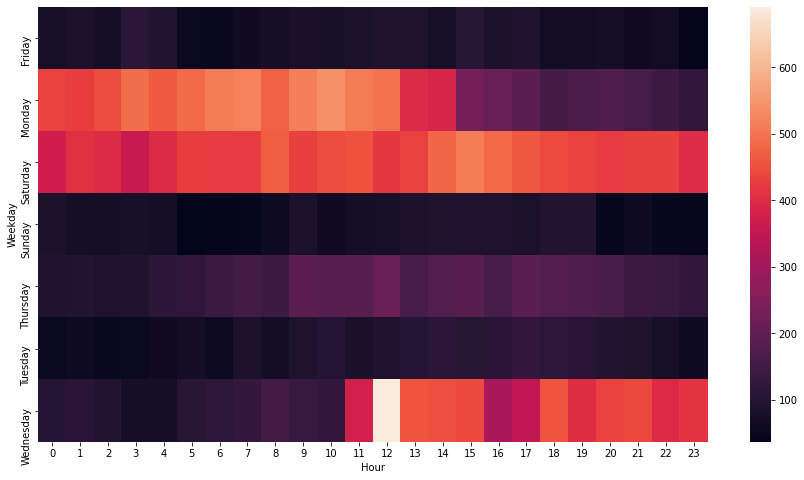

In [56]:
def heatmap(col1, col2):
  by_cross = df_raw.groupby([col1,col2]).apply(count_rows)
  pivot=by_cross.unstack()
  plt.figure(figsize=(15,8))
  return sns.heatmap(pivot)
#Heatmap by hour and day
heatmap('Weekday','Hour')

,Day,Hour,Minute
Month,,,
1,3216,9564,23865
2,3392,10146,26055
3,270366,151912,386835
4,3448,10688,27225
5,18424,74112,134895
6,33007,94015,234525
7,19873,34576,143805
8,747,3277,7575
9,948,4014,9810


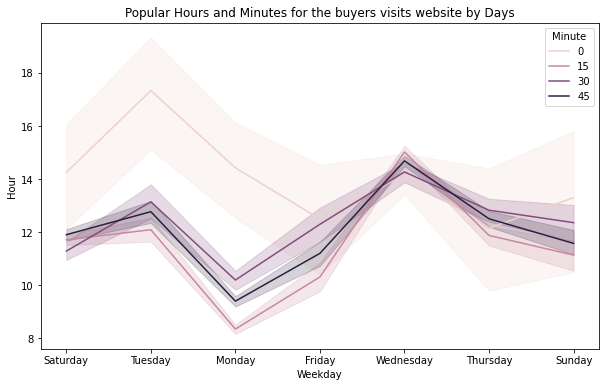

In [57]:
plt.figure(figsize=(10,6))
ax = sns.lineplot(x='Weekday',y='Hour', hue='Minute',data=df_raw)
ax.set_title('Popular Hours and Minutes for the buyers visits website by Days')
    
df_raw.groupby('Month')[['Day','Hour','Minute']].sum()

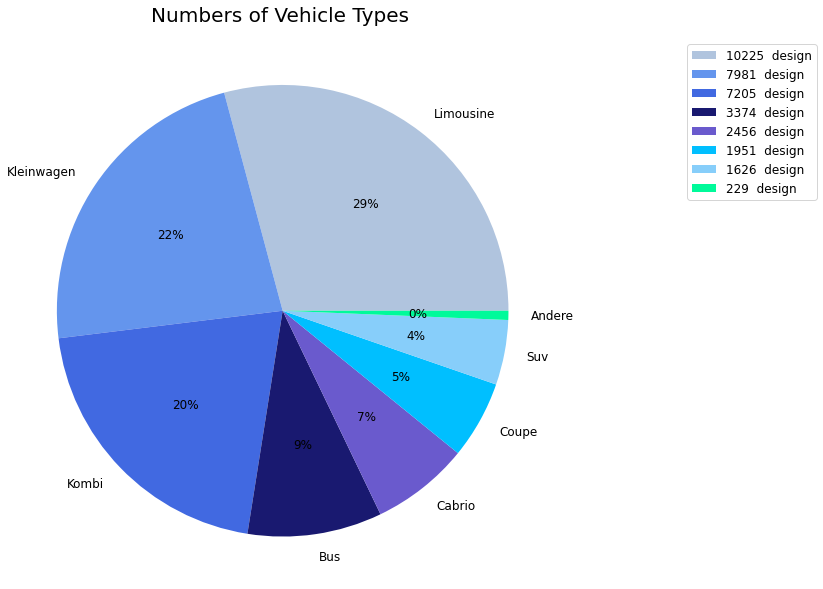

In [58]:
#Vehicle Type Count

vehicle_list = ['Limousine','Kleinwagen','Kombi', 'Bus','Cabrio','Coupe','Suv','Andere']
count_per_vehicle =[10225, 7981, 7205,3374,2456,1951,1626,229]

colors = [ 'lightsteelblue', 'cornflowerblue', 'royalblue', 'midnightblue','slateblue','deepskyblue','lightskyblue','mediumspringgreen'] 
count_per_vehicleType = [str(vehicleType)+"  design" for vehicleType in count_per_vehicle] 
fig = plt.gcf() 
plt.rcParams['font.size'] = 12.0
fig.set_size_inches(9,10) 
plt.pie(x = count_per_vehicle, labels = vehicle_list, autopct = '%i%%',
        radius = 15, colors = colors)
plt.title("Numbers of Vehicle Types", fontsize = 20, y=1.02) 
plt.axis('equal') #makes a circle pie chart (not oval)
plt.legend(bbox_to_anchor =(1.58,1), labels = count_per_vehicleType);

<AxesSubplot:title={'center':'Brand Vs Price'}, xlabel='brand', ylabel='Increase In price'>

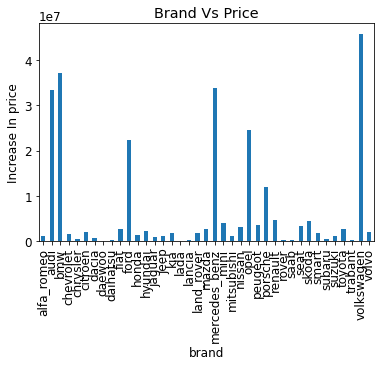

In [59]:
var = autos_df.groupby('brand').price.sum()
fig = plt.figure()
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Brand')
ax1.set_ylabel('Increase In price')
ax1.set_title("Brand Vs Price")
var.plot(kind='bar')

<AxesSubplot:title={'center':'Year Vs Price'}, xlabel='registration_year', ylabel='Increase In price'>

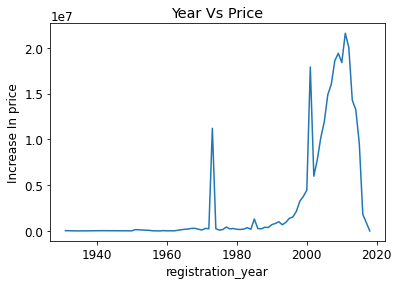

In [60]:
var = autos_df.groupby('registration_year').price.sum() 
fig = plt.figure()
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Year')
ax1.set_ylabel('Increase In price')
ax1.set_title("Year Vs Price")
var.plot(kind='line')